# 02 · Exploración del conjunto de desarrollo

**Machine Learning 1 · FIUNA · 2026**  
Hugo Rene Caniza Portillo y Ruben Dario Lopez Sanabria

Exploramos distribuciones, relaciones y cobertura de las muestras de **desarrollo**. Seleccionamos únicamente las filas asignadas a entrenamiento del corte histórico aprobado; excluimos la purga y la evaluación de enero–marzo de 2026 antes de calcular estadísticas o dibujar gráficos.

El notebook es independiente y requiere los datos locales autorizados y `requirements.txt`. No ajusta modelos, no consulta servicios externos y no modifica el experimento aprobado. El EDA es descriptivo: no usamos sus asociaciones para cambiar retrospectivamente variables, algoritmos o particiones. Los códigos de ubicación son anónimos y las coordenadas no se muestran.

**Acceso a datos:** la ejecución requiere las cuatro tablas de muestras, `particiones.json` y los archivos de integridad de `data/processed/`, con acceso autorizado. No se redistribuyen registros individuales. Las salidas agregadas y las figuras se conservan en este notebook para su lectura sin esos insumos.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Funciona tanto desde la raíz del proyecto como desde notebooks/.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'scripts/proyecto.json').is_file() and (p / 'scripts').is_dir())
sys.path.insert(0, str(ROOT / 'scripts'))
from procesar_datos import FEATURES, AGGREGATIONS, configured, sha, verify_samples

%matplotlib inline
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})
pd.set_option('display.max_columns', 24)

def read_json(path):
    return json.loads(path.read_text(encoding='utf-8'))

## 1. Selección explícita de desarrollo

Usamos los identificadores de las particiones oficiales, en lugar de cortar por porcentaje de filas. La pertenencia se comparte entre ventanas. Cada combinación horizonte–ventana tiene una fila por muestra; no concatenamos ambas ventanas para duplicar el tamaño de la población.

In [2]:
from entrenar import input_hashes

input_hashes(configured('datos'))
partitions = read_json(configured('datos') / 'particiones.json')
development = {}
for h in [0, 7]:
    split = partitions[str(h)]['historico']
    for w in [7, 14]:
        data = pd.read_csv(configured('datos') / f'muestras_h{h}_{w}d.csv').set_index('muestra_id', drop=False)
        development[(h, w)] = data.loc[split['train_ids']].copy()
        assert set(development[(h, w)].index).isdisjoint(split['validation_ids'] + split['purged_ids'])
        assert pd.to_datetime(development[(h, w)].fecha_objetivo).lt('2026-01-01').all()
        del data
    assert development[(h, 7)].index.equals(development[(h, 14)].index)

inventory = pd.DataFrame([{'horizonte': h, 'ventana': w, 'n': len(d),
    'negativos': int(d.y.eq(0).sum()), 'positivos': int(d.y.sum()),
    'ubicaciones': d.ubicacion_id.nunique(), 'inicio_etiqueta': d.fecha_objetivo.min(),
    'fin_etiqueta': d.fecha_objetivo.max()} for (h, w), d in development.items()])
display(inventory)

,horizonte,ventana,n,negativos,positivos,ubicaciones,inicio_etiqueta,fin_etiqueta
0,0,7,359,188,171,22,2024-09-02,2025-12-15
1,0,14,359,188,171,22,2024-09-02,2025-12-15
2,7,7,313,157,156,22,2024-09-09,2025-12-15
3,7,14,313,157,156,22,2024-09-09,2025-12-15


Desarrollo contiene 359 muestras h0 y 313 h7. Las ventanas de 7 y 14 días comparten los mismos objetivos dentro de cada horizonte. Estas cantidades, y no los tamaños históricos, son la base de todas las estadísticas siguientes.

## 2. Balance de clases

Comparamos las clases una sola vez por horizonte. El balance agregado puede ocultar cambios entre fechas y ubicaciones, por lo que lo acompañamos después con un análisis de cobertura.

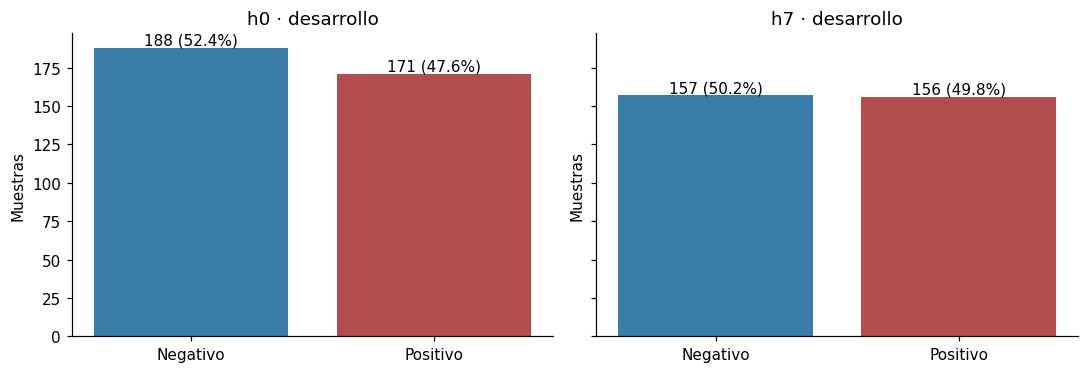

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for h, ax in zip([0, 7], axes):
    counts = development[(h, 7)].y.value_counts().reindex([0, 1], fill_value=0)
    ax.bar(['Negativo', 'Positivo'], counts, color=['#397da8', '#b34d4d'])
    ax.set(title=f'h{h} · desarrollo', ylabel='Muestras')
    for i, n in enumerate(counts):
        ax.text(i, n+2, f'{n} ({n/counts.sum():.1%})', ha='center')
plt.tight_layout()
plt.show()

En h0 hay 188 negativos y 171 positivos; en h7, 157 negativos y 156 positivos. El balance cambia entre horizontes porque h7 exige seguimiento exacto. La clase mayoritaria se calcula con cada entrenamiento, nunca con el bloque validado, aunque el balance global resulte cercano.

## 3. Estadísticas, faltantes y extremos

Mostramos las diez variables con sus unidades. Los mínimos y máximos abarcan la ventana completa; la lluvia se acumula y las medias resumen días completos. Los valores extremos válidos se conservan. Una temperatura bajo cero o una componente negativa del viento no se descartan automáticamente.

In [4]:
labels = ['HR media (%)', 'HR mínima (%)', 'HR máxima (%)',
          'T media (°C)', 'T mínima (°C)', 'T máxima (°C)',
          'Precipitación (mm)', 'Velocidad media (m/s)', 'Componente u (m/s)', 'Componente v (m/s)']
stats = []
for (h, w), data in development.items():
    table = data[FEATURES].describe().T[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']]
    table.insert(0, 'ventana', w)
    table.insert(0, 'horizonte', h)
    table['faltantes'] = data[FEATURES].isna().sum()
    stats.append(table)
display(pd.concat(stats).round(3))
assert all(np.isfinite(data[FEATURES]).all().all() for data in development.values())

,horizonte,ventana,count,mean,std,min,25%,50%,75%,max,faltantes
hr_media_pct,0,7,359.0,75.829,6.807,59.185,70.997,76.345,80.726,91.744,0
hr_min_pct,0,7,359.0,39.287,8.119,21.000,33.000,39.000,46.000,67.000,0
hr_max_pct,0,7,359.0,98.304,2.255,88.000,98.000,99.000,100.000,100.000,0
temperatura_media_c,0,7,359.0,18.996,2.568,10.551,17.390,19.278,20.604,25.222,0
temperatura_min_c,0,7,359.0,10.891,3.566,-1.200,8.600,11.200,13.600,18.800,0
temperatura_max_c,0,7,359.0,28.362,2.649,18.100,26.850,28.400,30.150,33.600,0
precipitacion_mm,0,7,359.0,41.716,32.544,0.000,14.450,35.900,61.550,176.600,0
viento_vel_media_10m_ms,0,7,359.0,2.853,0.638,1.595,2.388,2.778,3.277,5.038,0
viento_u_media_10m_ms,0,7,359.0,-0.830,0.864,-3.686,-1.297,-0.748,-0.295,1.374,0
viento_v_media_10m_ms,0,7,359.0,-0.824,0.720,-3.272,-1.256,-0.771,-0.313,1.213,0


No encontramos faltantes ni valores meteorológicos no finitos en las muestras de desarrollo incluidas. Esta cobertura es posterior a las reglas de inclusión: no demuestra que el monitoreo original fuera completo. Las escalas y unidades difieren; las gráficas conservan la escala física de cada variable y la regresión logística utiliza su propio escalado dentro del pipeline.

## 4. Histogramas: comparación de ventanas

Superponemos histogramas de densidad de 7 y 14 días con los mismos intervalos dentro de cada variable y horizonte. La densidad facilita comparar formas; no representa probabilidades de infección. Cada panel conserva su unidad y no mezclamos h0 con h7.

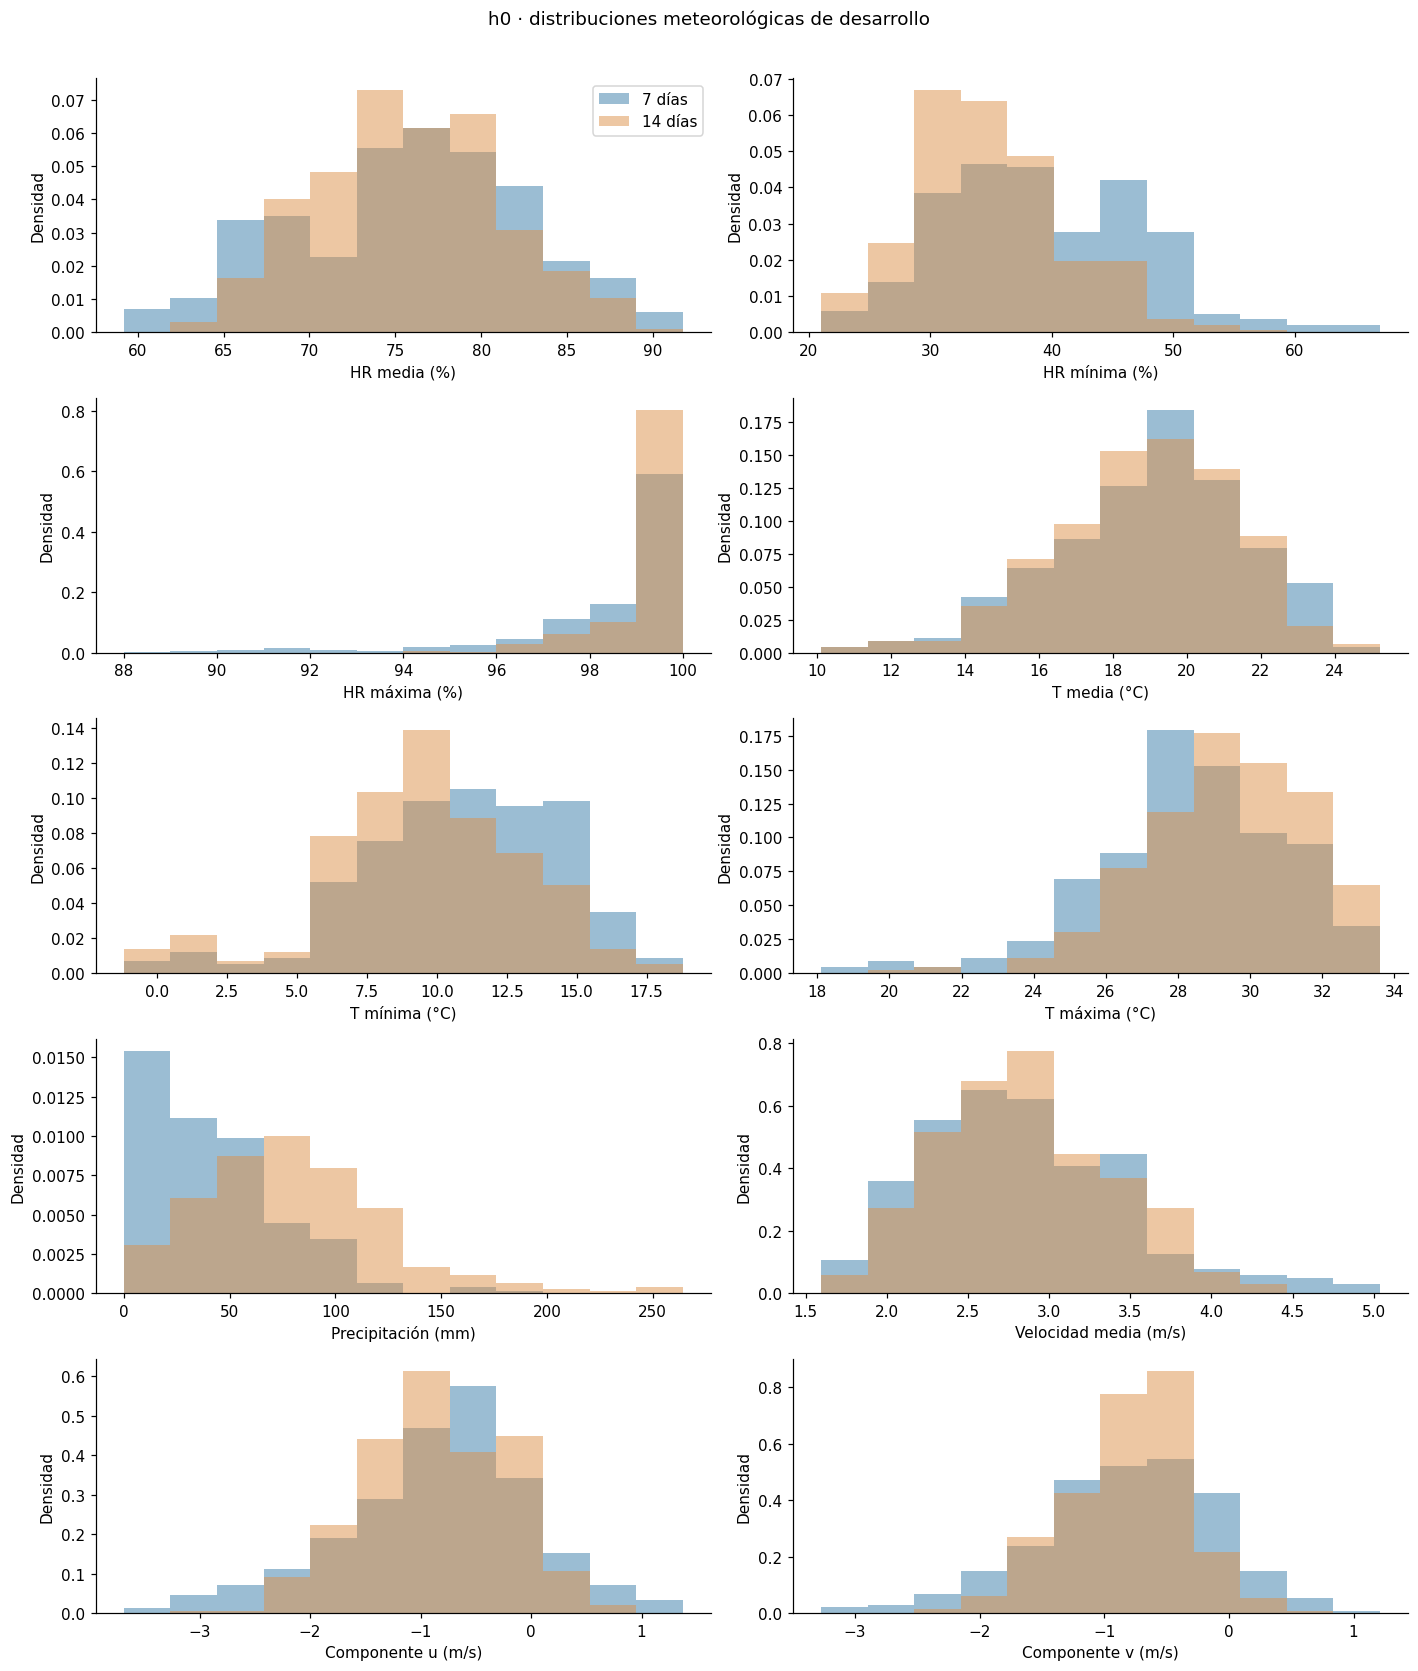

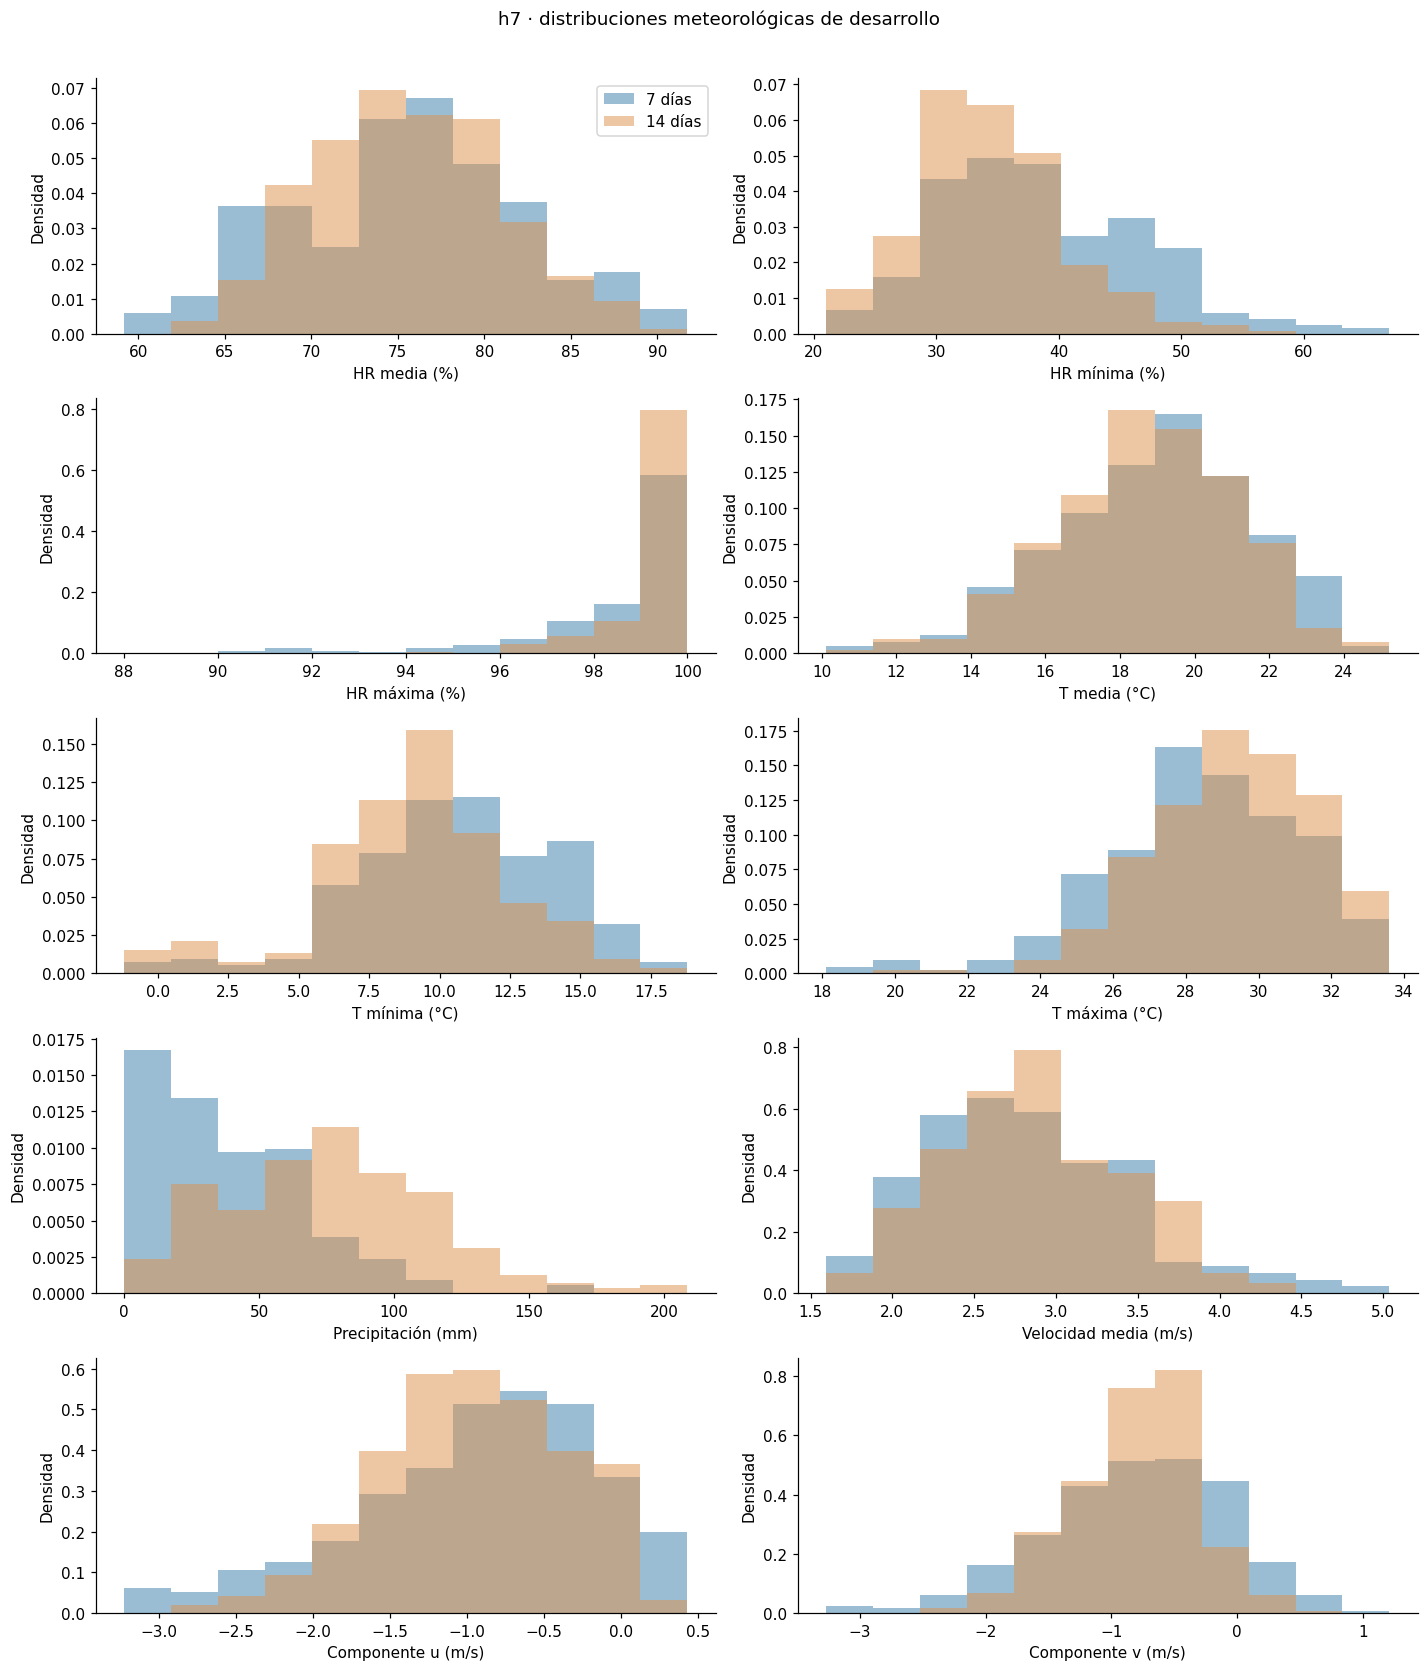

,horizonte,ventana,mediana_lluvia_mm,p95_lluvia_mm,máximo_lluvia_mm
0,0,7,35.9,99.11,176.6
1,0,14,79.1,159.73,264.2
2,7,7,33.1,95.84,173.6
3,7,14,76.6,137.10,208.6


In [5]:
for h in [0, 7]:
    fig, axes = plt.subplots(5, 2, figsize=(13, 15))
    for feature, label, ax in zip(FEATURES, labels, axes.flat):
        a, b = development[(h, 7)][feature], development[(h, 14)][feature]
        edges = np.histogram_bin_edges(pd.concat([a, b]), bins=12)
        ax.hist(a, bins=edges, density=True, alpha=.5, label='7 días', color='#397da8')
        ax.hist(b, bins=edges, density=True, alpha=.5, label='14 días', color='#dd9148')
        ax.set(xlabel=label, ylabel='Densidad')
    axes.flat[0].legend()
    fig.suptitle(f'h{h} · distribuciones meteorológicas de desarrollo', y=1.01)
    plt.tight_layout()
    plt.show()
rain = pd.DataFrame([{'horizonte': h, 'ventana': w,
    'mediana_lluvia_mm': data.precipitacion_mm.median(),
    'p95_lluvia_mm': data.precipitacion_mm.quantile(.95),
    'máximo_lluvia_mm': data.precipitacion_mm.max()} for (h,w),data in development.items()])
display(rain.round(2))

La lluvia acumulada presenta una cola derecha que la mediana y el percentil 95 ayudan a describir. Extender la ventana puede aumentar acumulados y ampliar extremos por construcción, sin que ello implique mayor riesgo. Para medias, una ventana más larga puede suavizar variaciones. Los histogramas describen estos cambios; no justifican por sí solos elegir una ventana.

## 5. Boxplots por clase y ventana

Comparamos mediana, rango intercuartílico y observaciones extremas de las diez variables. Cada panel muestra cuatro grupos: negativo/positivo de 7 días y negativo/positivo de 14 días. Los puntos fuera de los bigotes son observaciones, no errores confirmados.

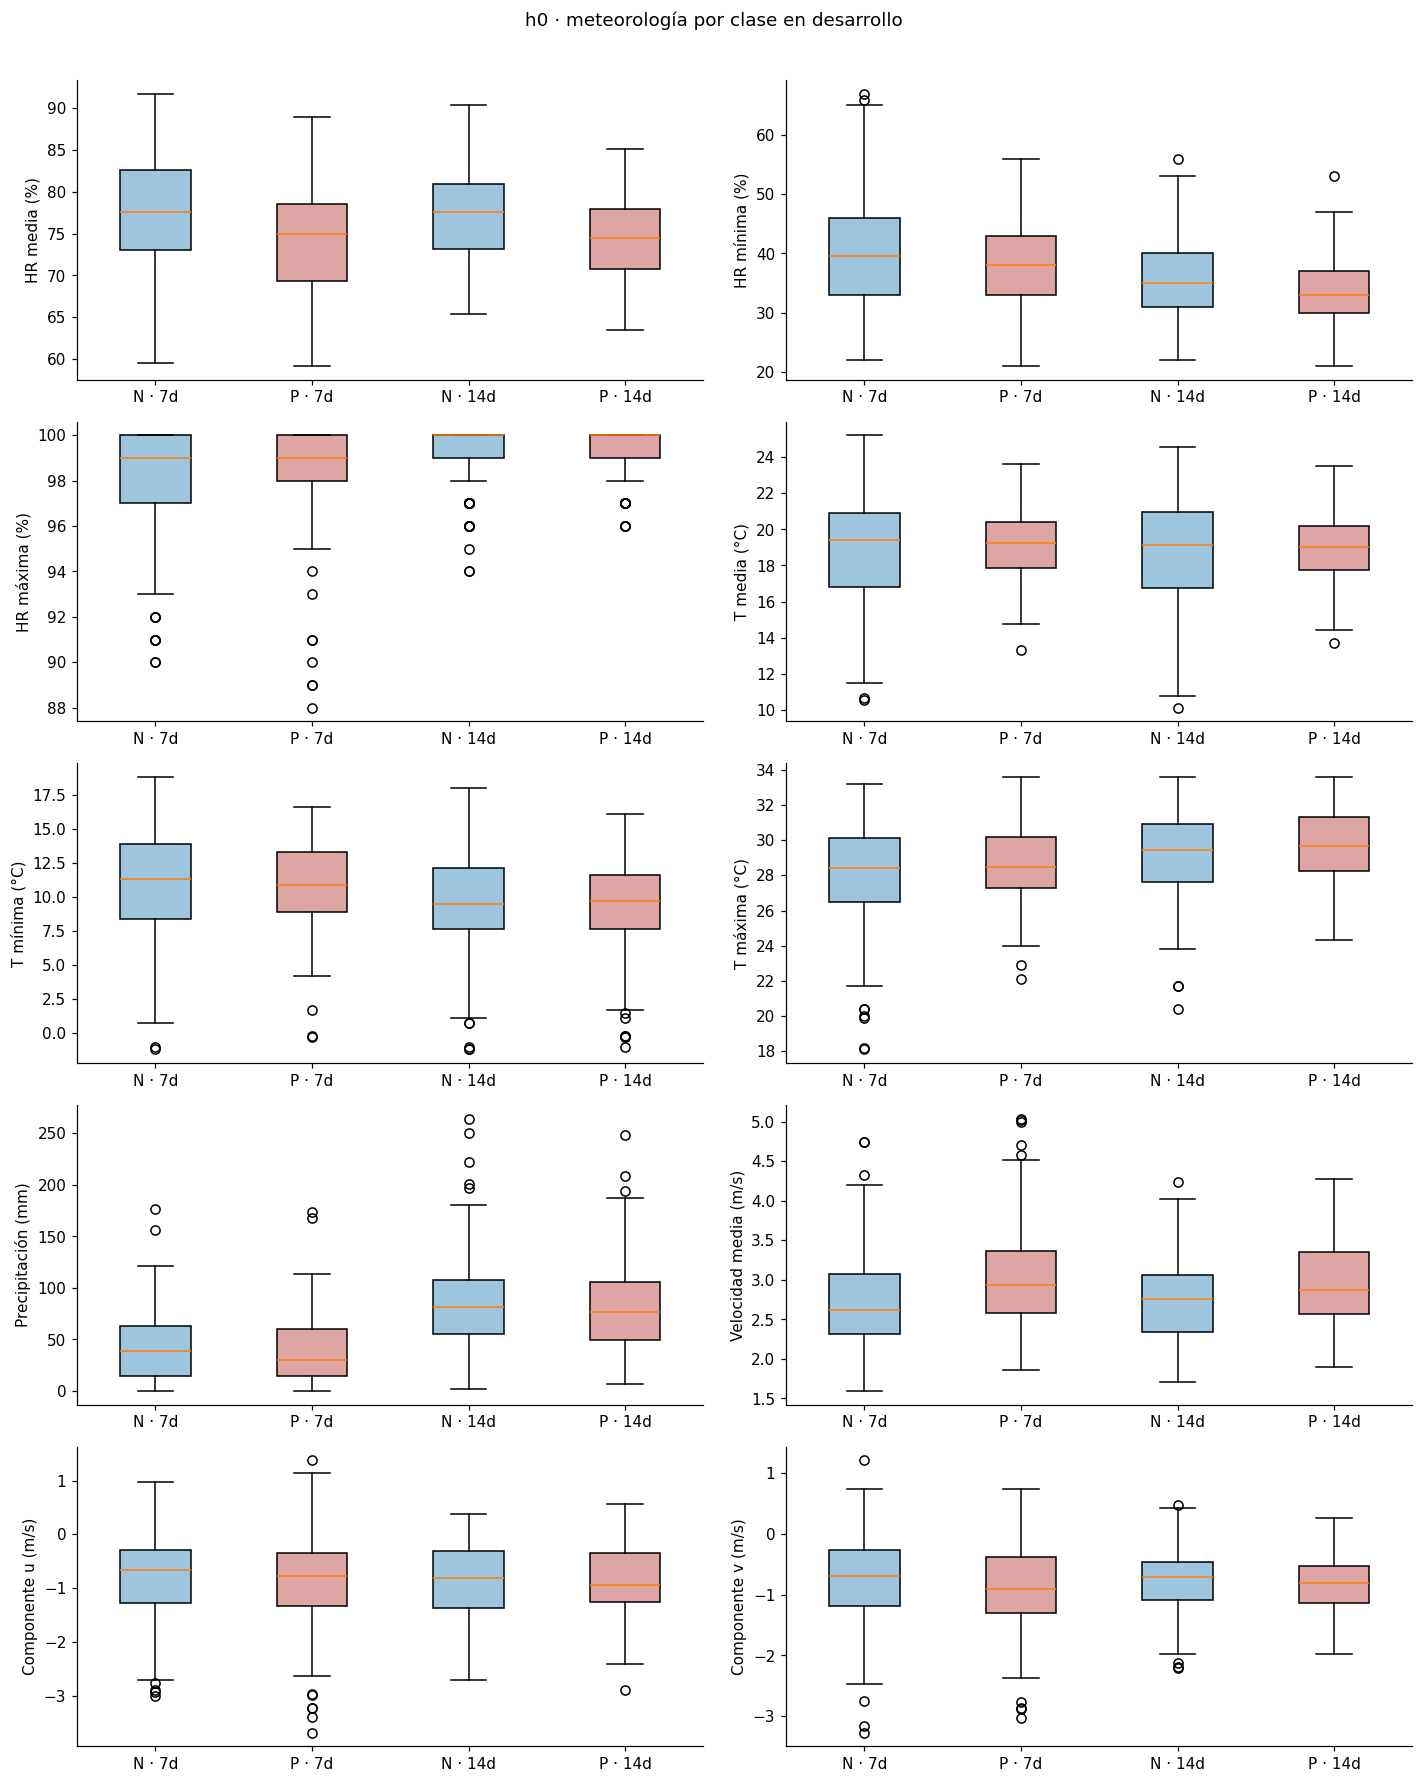

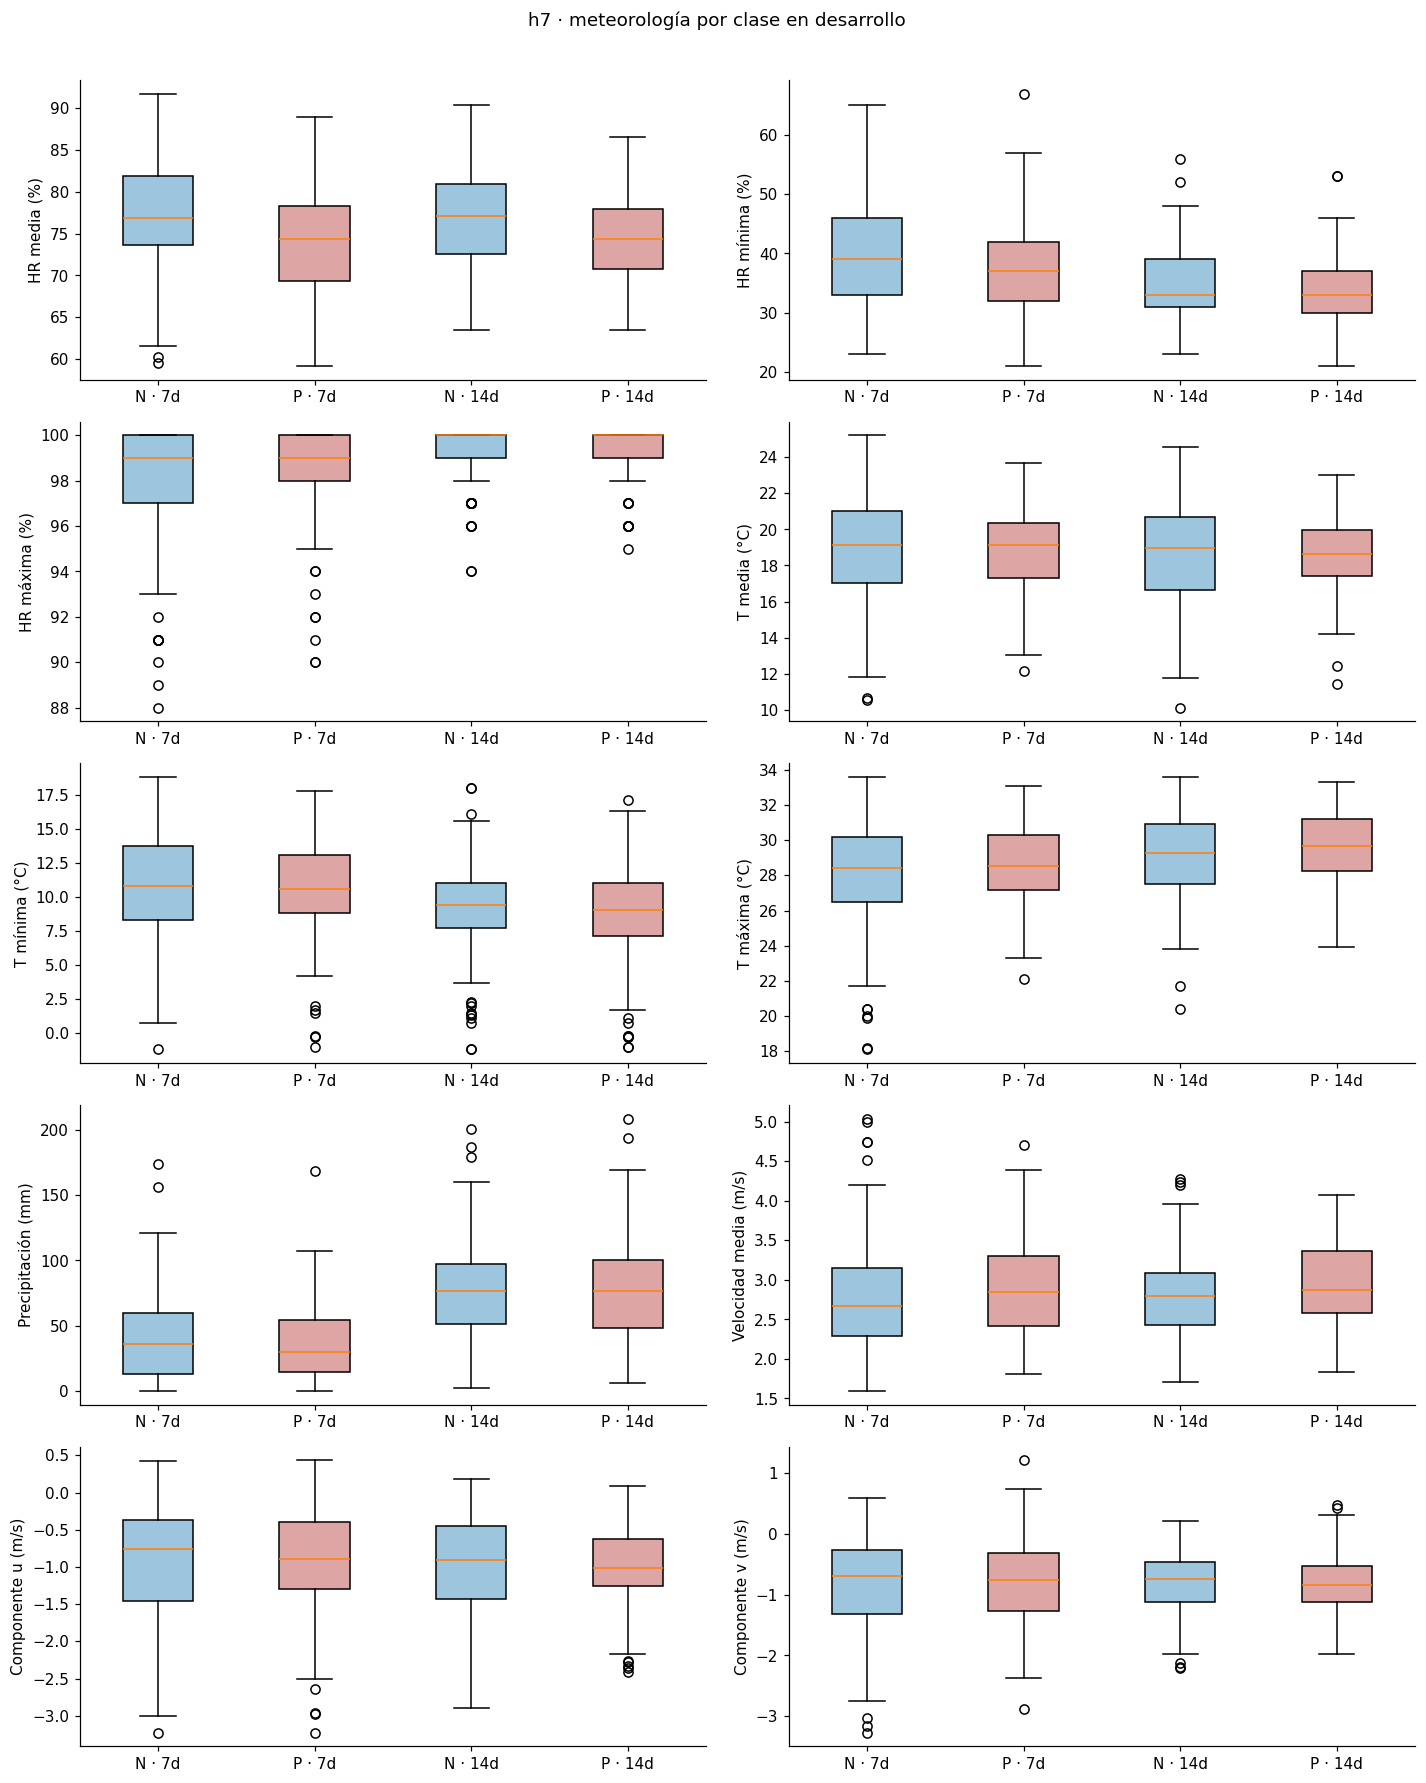

In [6]:
for h in [0, 7]:
    fig, axes = plt.subplots(5, 2, figsize=(13, 16))
    for feature, label, ax in zip(FEATURES, labels, axes.flat):
        groups = [development[(h, w)].loc[lambda d: d.y.eq(y), feature]
                  for w in [7, 14] for y in [0, 1]]
        boxes = ax.boxplot(groups, tick_labels=['N · 7d', 'P · 7d', 'N · 14d', 'P · 14d'], patch_artist=True)
        for box, color in zip(boxes['boxes'], ['#9ec5de', '#dea5a5']*2):
            box.set_facecolor(color)
        ax.set(ylabel=label)
    fig.suptitle(f'h{h} · meteorología por clase en desarrollo', y=1.01)
    plt.tight_layout()
    plt.show()

Los rangos por clase se superponen en múltiples variables: no observamos una separación perfecta mediante un único resumen meteorológico. Las diferencias de mediana no demuestran causalidad ni un umbral agronómico. Además, las observaciones de una ubicación se repiten en el tiempo, por lo que no interpretamos estos boxplots como comparaciones entre muestras independientes.

## 6. Correlaciones entre predictores

Calculamos Pearson dentro de desarrollo, por horizonte y ventana. Excluimos identificadores, coordenadas y etiquetas de las matrices. Las correlaciones describen relaciones lineales y no capturan todas las dependencias posibles.

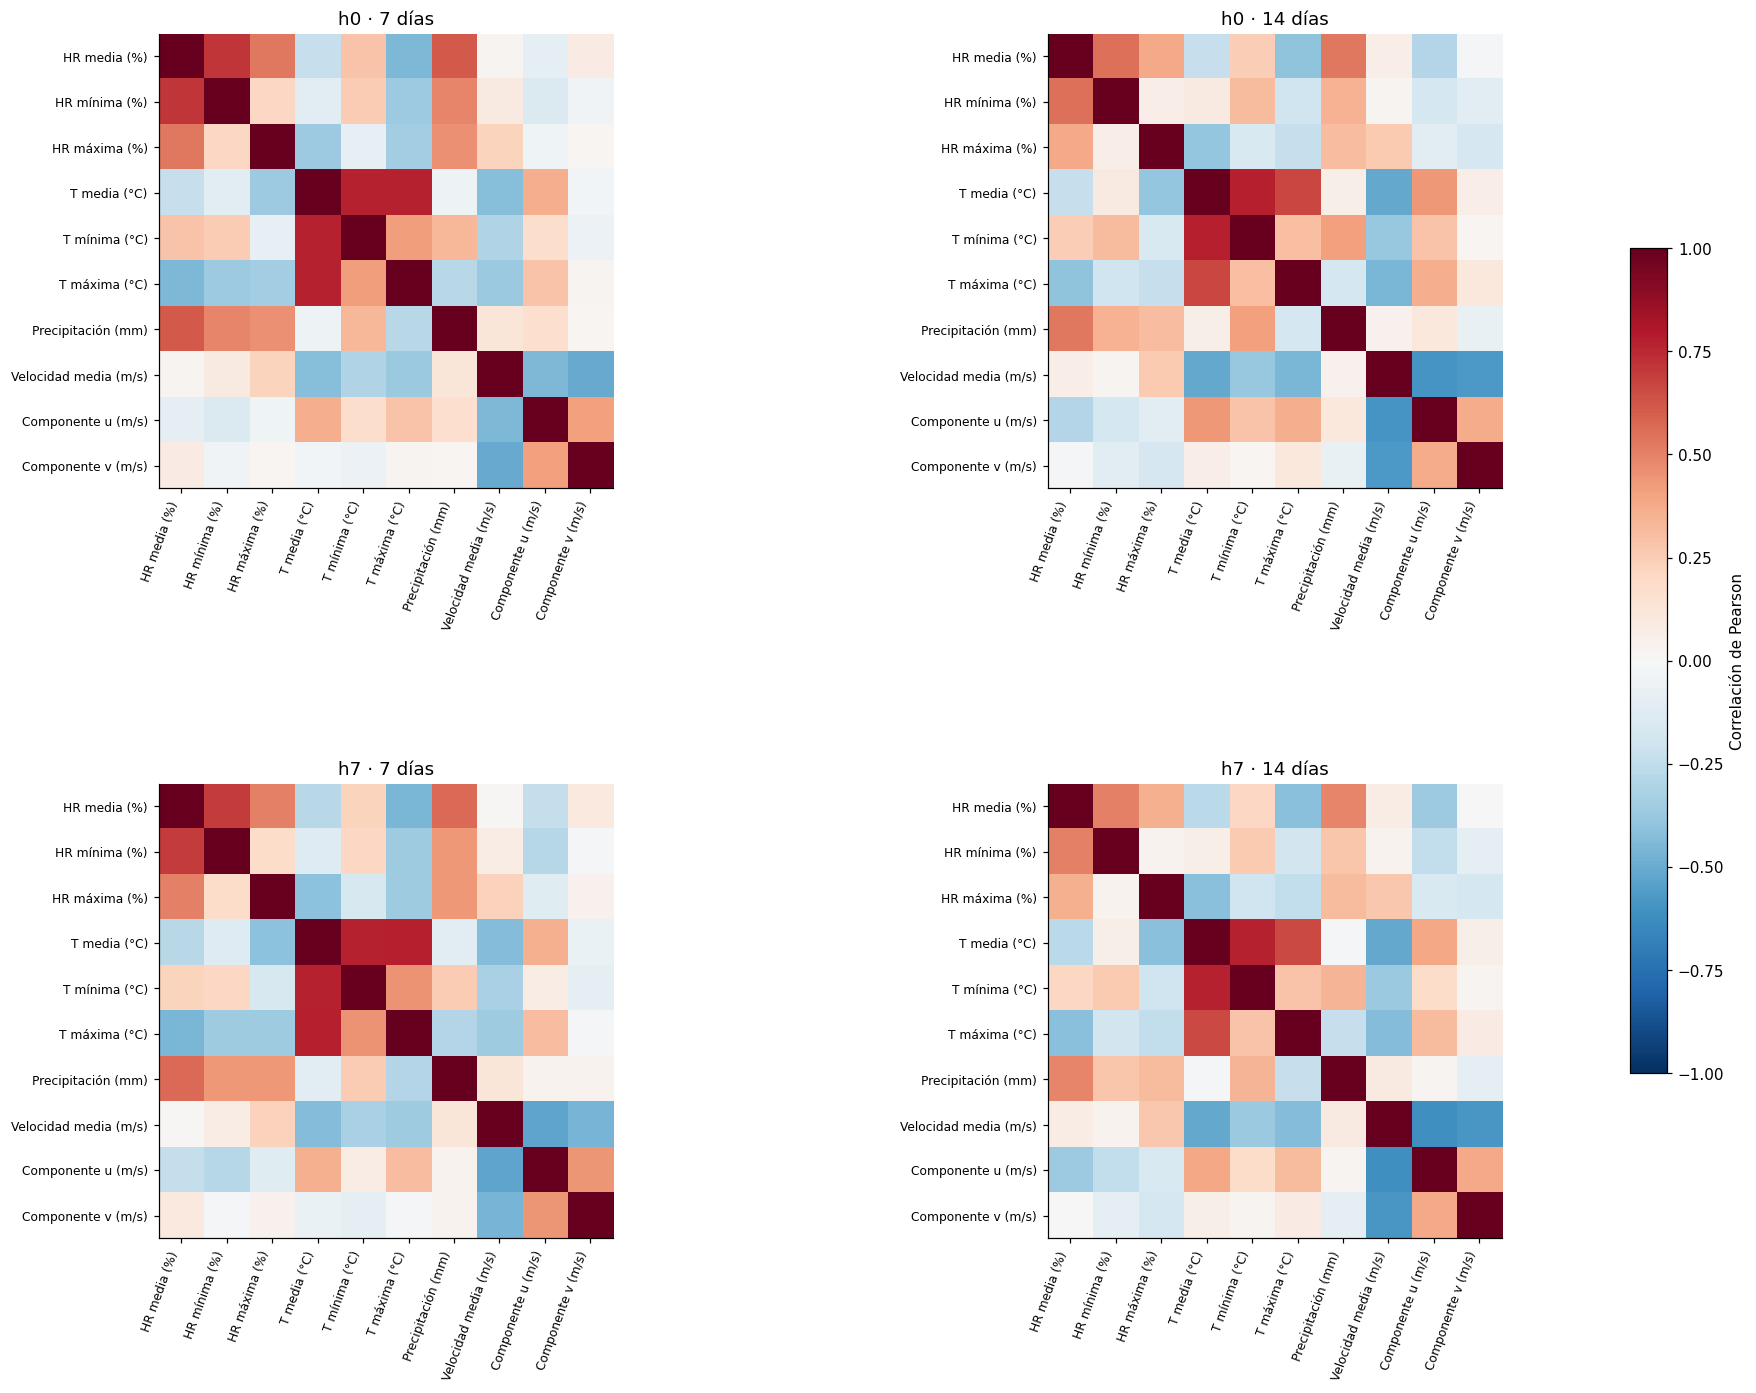

,horizonte,ventana,variable_1,variable_2,r
0,0,7,temperatura_media_c,temperatura_max_c,0.770
1,0,14,temperatura_media_c,temperatura_min_c,0.781
2,7,7,temperatura_media_c,temperatura_max_c,0.778
3,7,14,temperatura_media_c,temperatura_min_c,0.771


In [7]:
fig, axes = plt.subplots(2, 2, figsize=(17, 15))
strongest = []
for (h, w), ax in zip(development, axes.flat):
    corr = development[(h, w)][FEATURES].corr()
    im = ax.imshow(corr, vmin=-1, vmax=1, cmap='RdBu_r')
    ax.set_xticks(range(10), labels=labels, rotation=70, ha='right', fontsize=8)
    ax.set_yticks(range(10), labels=labels, fontsize=8)
    ax.set_title(f'h{h} · {w} días')
    mask = np.triu(np.ones(corr.shape, dtype=bool), k=1)
    pairs = corr.where(mask).stack()
    pair = pairs.abs().idxmax()
    strongest.append({'horizonte': h, 'ventana': w, 'variable_1': pair[0],
                       'variable_2': pair[1], 'r': corr.loc[pair]})
fig.subplots_adjust(wspace=.7, hspace=.65, right=.88, bottom=.15)
color_axis = fig.add_axes([.93, .25, .02, .5])
fig.colorbar(im, cax=color_axis, label='Correlación de Pearson')
plt.show()
display(pd.DataFrame(strongest).round(3))

Las correlaciones más altas de la tabla revelan redundancia entre resúmenes de las mismas familias meteorológicas. No eliminamos variables después de observarlas: mantenemos el contrato de diez predictores del experimento aprobado. Una correlación alta tampoco garantiza utilidad predictiva; esa evaluación corresponde a los folds temporales.

## 7. Cobertura temporal y frecuencia de positivos

Contamos muestras por fecha de etiqueta y calculamos la proporción positiva observada. Dibujamos puntos, sin interpolar resultados entre fechas ni atravesar intervalos sin seguimiento. Una fecha sin registros no equivale a una fecha sin roya.

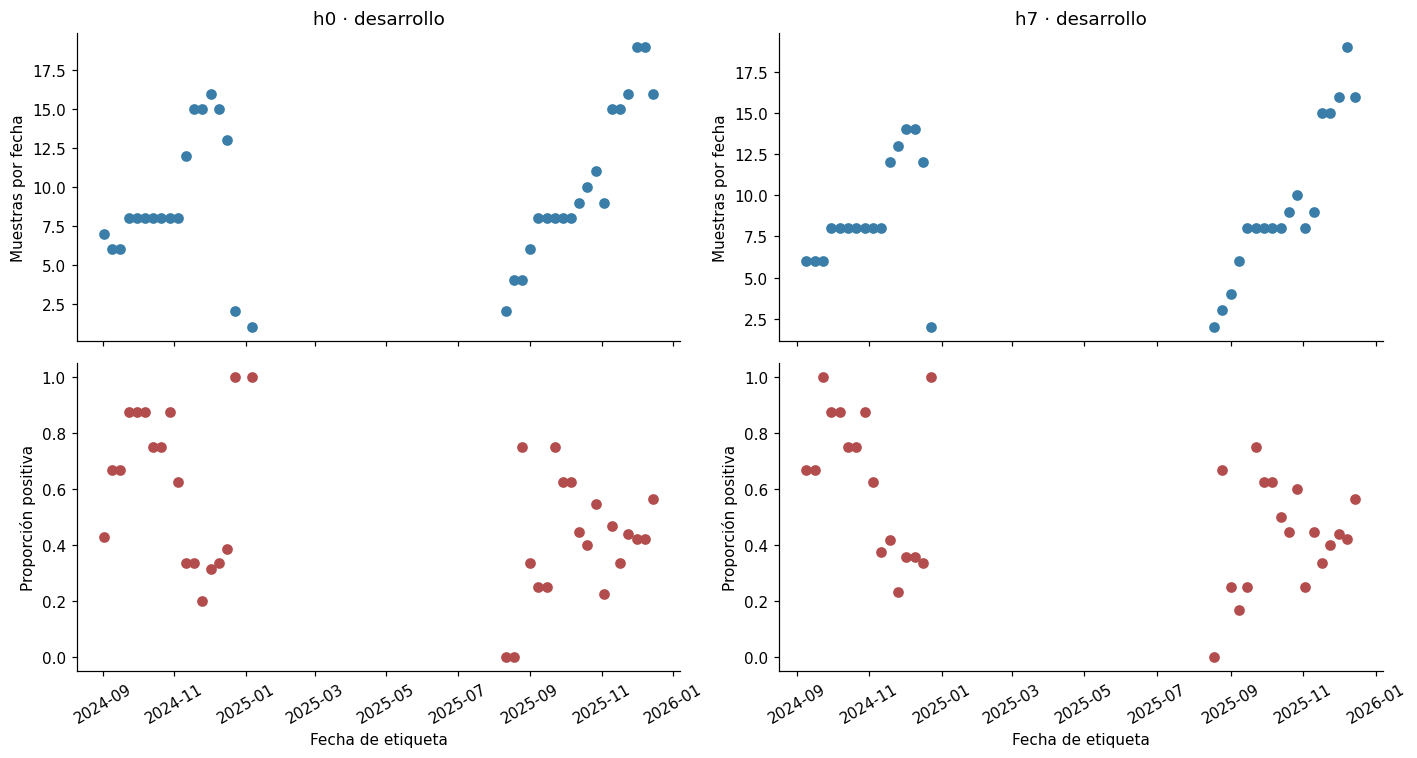

,horizonte,fechas_observadas,mediana_intervalo_días,máximo_intervalo_días
0,0,37,7.0,217.0
1,7,34,7.0,238.0


In [8]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex='col')
gaps = []
for col, h in enumerate([0, 7]):
    data = development[(h, 7)]
    temporal = data.groupby('fecha_objetivo').y.agg(n='size', positivos='sum')
    temporal.index = pd.to_datetime(temporal.index)
    axes[0, col].scatter(temporal.index, temporal.n, color='#397da8')
    axes[0, col].set(title=f'h{h} · desarrollo', ylabel='Muestras por fecha')
    axes[1, col].scatter(temporal.index, temporal.positivos/temporal.n, color='#b34d4d')
    axes[1, col].set(ylabel='Proporción positiva', ylim=(-.05, 1.05), xlabel='Fecha de etiqueta')
    intervals = temporal.index.to_series().diff().dt.days.dropna()
    gaps.append({'horizonte': h, 'fechas_observadas': len(temporal),
                 'mediana_intervalo_días': intervals.median(), 'máximo_intervalo_días': intervals.max()})
    for ax in axes[:, col]:
        ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()
display(pd.DataFrame(gaps))

La cobertura presenta un intervalo prolongado entre campañas y tamaños variables por fecha. Las proporciones extremas pueden surgir de pocas muestras y no representan prevalencia regional. Los folds semanales aprobados evitan atravesar ese intervalo dentro de un bloque de validación, aunque el primer entrenamiento pertenece principalmente a la campaña anterior.

## 8. Cobertura por ubicación

Asignamos códigos U01, U02, … solo para visualizar la cobertura, sin mostrar la correspondencia con coordenadas o IDs de origen. Contamos una muestra por horizonte y fecha, usando una sola ventana. Estos códigos no entran al modelo.

,ubicación,n,positivos,horizonte,proporción_positiva
0,U01,31,12,0,0.387
1,U02,7,1,0,0.143
2,U03,34,20,0,0.588
3,U04,10,3,0,0.300
4,U05,12,5,0,0.417
5,U06,5,2,0,0.400
6,U07,14,3,0,0.214
7,U08,28,16,0,0.571
8,U09,9,2,0,0.222
9,U10,3,3,0,1.000


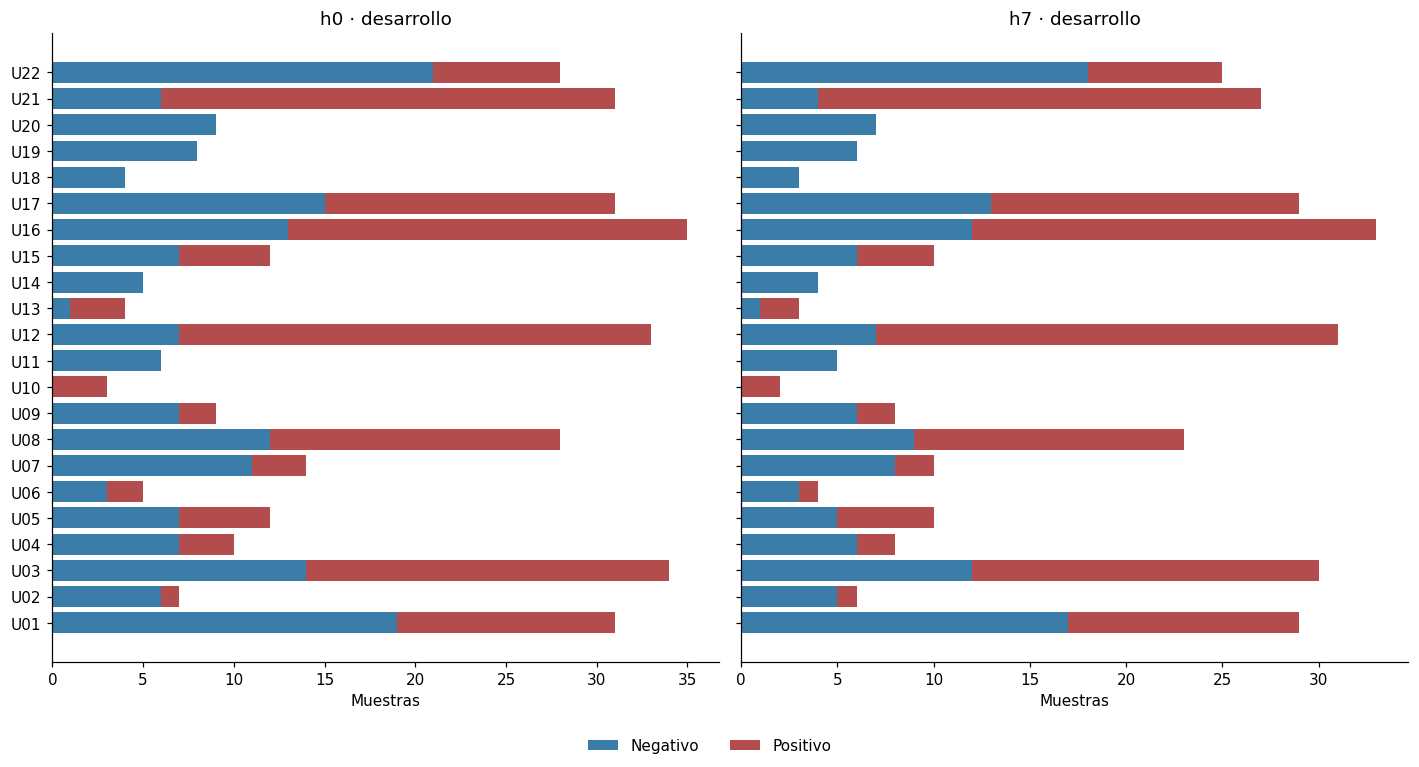

In [9]:
locations = sorted(set().union(*(set(d.ubicacion_id) for d in development.values())))
anonymous = {location: f'U{i:02d}' for i, location in enumerate(locations, 1)}
coverage = []
for h in [0, 7]:
    table = development[(h, 7)].groupby('ubicacion_id').y.agg(n='size', positivos='sum')
    table.index = table.index.map(anonymous)
    table['horizonte'] = h
    coverage.append(table.rename_axis('ubicación'))
coverage = pd.concat(coverage).reset_index()
coverage['proporción_positiva'] = coverage.positivos / coverage.n
display(coverage.round(3))
fig, axes = plt.subplots(1, 2, figsize=(13, 7), sharey=True)
for h, ax in zip([0, 7], axes):
    table = coverage[coverage.horizonte.eq(h)].set_index('ubicación').reindex(anonymous.values())
    ax.barh(table.index, table.n-table.positivos, label='Negativo', color='#397da8')
    ax.barh(table.index, table.positivos, left=table.n-table.positivos, label='Positivo', color='#b34d4d')
    ax.set(title=f'h{h} · desarrollo', xlabel='Muestras')
handles, legend_labels = axes[0].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc='lower center', ncol=2, frameon=False)
plt.tight_layout(rect=[0, .05, 1, 1])
plt.show()

La cantidad de registros y el balance de clases varían entre ubicaciones. Los lugares más seguidos aportan más peso al ajuste y a las métricas agregadas. La separación temporal permite repetir ubicaciones entre entrenamiento y validación; por eso los resultados no estiman rendimiento en localidades nunca observadas.

## 9. Comparación emparejada de ventanas

Como cada horizonte conserva los mismos objetivos en ambas ventanas, calculamos diferencias emparejadas 14d−7d. No mezclamos las unidades de las variables ni interpretamos esos cambios como una mejora predictiva.

In [10]:
differences = []
for h in [0, 7]:
    a, b = development[(h, 7)], development[(h, 14)]
    assert a.index.equals(b.index) and a.y.equals(b.y)
    delta = b[FEATURES] - a[FEATURES]
    for feature, label in zip(FEATURES, labels):
        differences.append({'horizonte': h, 'variable': label,
                            'mediana_delta': delta[feature].median(),
                            'media_delta': delta[feature].mean()})
display(pd.DataFrame(differences).round(3))

,horizonte,variable,mediana_delta,media_delta
0,0,HR media (%),0.527,-0.084
1,0,HR mínima (%),0.000,-4.521
2,0,HR máxima (%),0.000,0.978
3,0,T media (°C),-0.187,-0.133
4,0,T mínima (°C),0.000,-1.413
5,0,T máxima (°C),0.000,1.049
6,0,Precipitación (mm),33.200,39.072
7,0,Velocidad media (m/s),-0.004,-0.002
8,0,Componente u (m/s),-0.082,-0.048
9,0,Componente v (m/s),0.014,0.007


La precipitación acumulada y los extremos cambian en parte por la definición de una ventana más larga; la comparación no equivale a incorporar observaciones independientes. La utilidad de 14 frente a 7 días se juzga con los resultados de validación ya aprobados, no con estas diferencias descriptivas.

## Conclusiones del EDA

Encontramos predictores completos en las muestras incluidas, escalas heterogéneas, correlaciones entre resúmenes, superposición de clases y cobertura temporal y geográfica desigual. Estas observaciones ayudan a explicar las limitaciones del estudio, sin atribuir causalidad ni modificar retrospectivamente el experimento. En este notebook no calculamos estadísticas ni gráficos sobre la evaluación histórica.